In [ ]:
import torch
import torch.nn as nn

from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

from torch import GradScaler
from torch import autocast
from torch.optim import AdamW
from torch.nn.utils import clip_grad_norm_
from torch.optim.lr_scheduler import CosineAnnealingLR

In [ ]:
class config():
  batch_size=64
  lr_rate=3e-5
  weight_decay=1e-4
  device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
  seed=42
  epochs=22
  num_classes=10
  grad_clip=1.0
  image_size=224
  num_workers=4

cf=config()

In [ ]:
train_transforms= transforms.Compose([
  transforms.Resize((cf.image_size, cf.image_size)),
  transforms.RandomHorizontalFlip(),
  transforms.RandomCrop(cf.image_size, padding=4),
  transforms.ToTensor(),
  transforms.Normalize(
    mean=[0.4914, 0.4822, 0.4465],
    std=[0.2470, 0.2435, 0.2616]
  )
])

test_transforms= transforms.Compose([
  transforms.Resize((cf.image_size, cf.image_size)),
  transforms.ToTensor(),
  transforms.Normalize(
    mean=[0.4914, 0.4822, 0.4465],
    std=[0.2470, 0.2435, 0.2616]
  )
])

In [ ]:
def get_dataloaders(batch_size, train_transforms, test_transforms):
  train_datasets= datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transforms
  )
  test_datasets=datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transforms
  )

  train_loader= DataLoader(
    train_datasets,
    batch_size=cf.batch_size,
    shuffle=True,
    num_workers= cf.num_workers,
    pin_memory=True,
    persistent_workers= (cf.num_workers>0),
    prefetch_factor=2 if cf.num_workers>0 else None
  )

  test_loader=DataLoader(
    test_datasets,
    batch_size=cf.batch_size,
    num_workers= cf.num_workers,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
  )

  return train_loader, test_loader


In [ ]:
class VGGClassifier(nn.Module):
  def __init__(self):
    super().__init__()

    self.block1= nn.Sequential(
      nn.Conv2d(3, 64, 3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),


      nn.Conv2d(64, 64, 3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.block2= nn.Sequential(
      nn.Conv2d(64, 128, 3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),

      nn.Conv2d(128, 128, 3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.block3=nn.Sequential(
      nn.Conv2d(128, 256, 3, padding=1),
      nn.BatchNorm2d(256),
      nn.ReLU(),

      nn.Conv2d(256, 256, 3, padding=1),
      nn.BatchNorm2d(256),
      nn.ReLU(),

      nn.Conv2d(256, 256, 3, padding=1),
      nn.BatchNorm2d(256),
      nn.ReLU(),

    )

    self.block4=nn.Sequential(
      nn.Conv2d(256, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.block5=nn.Sequential(
      nn.Conv2d(512,512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.Conv2d(512, 512, 3, padding=1),
      nn.BatchNorm2d(512),
      nn.ReLU(),

      nn.MaxPool2d(2)
    )

    self.classifier=nn.Sequential(
      nn.AdaptiveAvgPool2d(output_size=(1,1)),
      nn.Flatten(),

      nn.Linear(512, 256),
      nn.BatchNorm1d(256),
      nn.ReLU(),
      nn.Dropout(0.2),

      nn.Linear(256, 10)
    )

  def forward(self, x):
      x= self.block1(x)
      x= self.block2(x)
      x= self.block3(x)
      x= self.block4(x)
      x= self.block5(x)

      x= self.classifier(x)

      return x



In [ ]:
model= VGGClassifier()

In [ ]:
train_loader, test_loader= get_dataloaders(cf.batch_size, train_transforms, test_transforms)

optimizer=AdamW(
  model.parameters(),
  lr=cf.lr_rate,
  weight_decay=cf.weight_decay
)
scheduler = CosineAnnealingLR(optimizer,
                              T_max=cf.epochs,
                              eta_min=1e-6)

criterion=nn.CrossEntropyLoss()
scaler= GradScaler()


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
def validation(model, test_loader):
  model.eval()
  val_loss=0.0
  correct=0
  total=0

  with torch.no_grad():
    for batch_idx, (features, labels) in enumerate(test_loader):
      features=features.to(cf.device)
      labels=labels.to(cf.device)

      use_amp = torch.cuda.is_available() and cf.device.type == "cuda"
      with autocast(device_type="cuda",
                    dtype=torch.float16,
                    enabled=use_amp):
        logits=model(features)
        loss=criterion(logits, labels)

      val_loss+=loss.item()
      pred=logits.argmax(dim=1)
      correct+=(pred==labels).sum().item()
      total+=labels.size(0)
    val_acc=correct/total
    val_loss /= len(test_loader)
    return val_loss, val_acc

In [ ]:
from tqdm.auto import tqdm

train_losses = []
val_losses = []
val_accuracies = []
lrs = []

def train_model(model):
    os.makedirs("./checkpoints", exist_ok=True)

    best_acc = 0.0
    patience = 3
    counter = 0

    model.to(cf.device)

    for epoch in range(cf.epochs):

        model.train()

        running_loss = 0.0
        running_correct = 0
        running_total = 0

        pbar = tqdm(
            enumerate(train_loader),
            total=len(train_loader),
            desc=f"Epoch {epoch+1}/{cf.epochs}"
        )

        for batch_idx, (features, labels) in pbar:

            features = features.to(cf.device)
            labels = labels.to(cf.device)

            optimizer.zero_grad(set_to_none=True)

            use_amp = (
                torch.cuda.is_available()
                and cf.device.type == "cuda"
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):
                logits = model(features)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                cf.grad_clip
            )

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

            preds = logits.argmax(dim=1)

            running_correct += (preds == labels).sum().item()
            running_total += labels.size(0)

            batch_acc = (preds == labels).float().mean().item()

            pbar.set_postfix({
                "batch": f"{batch_idx+1}/{len(train_loader)}",
                "loss": f"{running_loss / (batch_idx + 1):.4f}",
                "acc": f"{running_correct / running_total * 100:.2f}%"
            })

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = running_correct / running_total

        train_losses.append(epoch_loss)

        val_loss, val_acc = validation(model, test_loader)

        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        scheduler.step()
        lrs.append(optimizer.param_groups[0]["lr"])

        if val_acc > best_acc:
            best_acc = val_acc
            counter = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_acc": best_acc
            }, "./checkpoints/best_model.pth")

        else:
            counter += 1

        print(
            f"\nEpoch [{epoch+1}/{cf.epochs}] Summary\n"
            f"Train Loss: {epoch_loss:.4f} | "
            f"Train Acc: {epoch_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"Best Acc: {best_acc*100:.2f}%"
        )

        if counter >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break


In [ ]:
train_model(model)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 1/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [1/22] Summary
Train Loss: 1.4470 | Train Acc: 48.40% | Val Loss: 1.5340 | Val Acc: 47.54% | Best Acc: 47.54%


Epoch 2/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [2/22] Summary
Train Loss: 1.0257 | Train Acc: 64.87% | Val Loss: 0.9873 | Val Acc: 66.22% | Best Acc: 66.22%


Epoch 3/22:   0%|          | 0/782 [00:00<?, ?it/s]

... (16 outputs left out)


Epoch [11/22] Summary
Train Loss: 0.2874 | Train Acc: 90.76% | Val Loss: 0.5863 | Val Acc: 80.45% | Best Acc: 82.73%


Epoch 12/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [12/22] Summary
Train Loss: 0.2567 | Train Acc: 91.79% | Val Loss: 0.4514 | Val Acc: 84.43% | Best Acc: 84.43%


Epoch 13/22:   0%|          | 0/782 [00:00<?, ?it/s]

In [ ]:
import torch
from tqdm.auto import tqdm

checkpoint_path = "./checkpoints/best_model.pth"

# Load checkpoint
checkpoint = torch.load(checkpoint_path, map_location=cf.device)

# Restore model weights and move to correct device
model.load_state_dict(checkpoint["model_state_dict"])
model.to(cf.device)   # CRITICAL: ensures all weights/biases land on GPU in float32

# Restore optimizer + scheduler
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

# Move optimizer state tensors to GPU (they load on CPU by default)
for state in optimizer.state.values():
    for k, v in state.items():
        if isinstance(v, torch.Tensor):
            state[k] = v.to(cf.device)

# Restore scaler state if saved, else reset cleanly
if "scaler_state_dict" in checkpoint:
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
else:
    scaler = torch.cuda.amp.GradScaler()

# Restore tracking variables
start_epoch = checkpoint["epoch"] + 1
best_acc = checkpoint["best_acc"]

print(f"Resumed training from epoch {start_epoch}")
print(f"Best accuracy so far: {best_acc * 100:.2f}%")

# ---- UPDATED TRAIN LOOP START ----

for epoch in range(start_epoch, cf.epochs):

    model.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    pbar = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch+1}/{cf.epochs}"
    )

    for batch_idx, (features, labels) in pbar:

        features = features.to(cf.device)
        labels = labels.to(cf.device)

        optimizer.zero_grad(set_to_none=True)

        use_amp = (
            torch.cuda.is_available()
            and cf.device.type == "cuda"
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(features)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            cf.grad_clip
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        preds = logits.argmax(dim=1)

        running_correct += (preds == labels).sum().item()
        running_total += labels.size(0)

        pbar.set_postfix({
            "batch": f"{batch_idx+1}/{len(train_loader)}",
            "loss": f"{running_loss / (batch_idx + 1):.4f}",
            "acc": f"{running_correct / running_total * 100:.2f}%"
        })

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = running_correct / running_total

    train_losses.append(epoch_loss)

    val_loss, val_acc = validation(model, test_loader)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    scheduler.step()
    lrs.append(optimizer.param_groups[0]["lr"])

    # Save best model
    if val_acc > best_acc:
        best_acc = val_acc

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_acc": best_acc
        }, "./checkpoints/best_model.pth")

    print(
        f"\nEpoch [{epoch+1}/{cf.epochs}] Summary\n"
        f"Train Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Best Acc: {best_acc*100:.2f}%"
    )

Resumed training from epoch 12
Best accuracy so far: 84.43%


/tmp/ipykernel_3985/3993549244.py:27: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Epoch 13/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [13/22] Summary
Train Loss: 0.2237 | Train Acc: 92.95% | Val Loss: 0.4490 | Val Acc: 84.72% | Best Acc: 84.72%


Epoch 14/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [14/22] Summary
Train Loss: 0.1906 | Train Acc: 94.27% | Val Loss: 0.3887 | Val Acc: 86.67% | Best Acc: 86.67%


... (9 outputs left out)


Epoch [19/22] Summary
Train Loss: 0.0856 | Train Acc: 98.11% | Val Loss: 0.3346 | Val Acc: 88.85% | Best Acc: 88.89%


Epoch 20/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [20/22] Summary
Train Loss: 0.0763 | Train Acc: 98.46% | Val Loss: 0.3244 | Val Acc: 89.22% | Best Acc: 89.22%


Epoch 21/22:   0%|          | 0/782 [00:00<?, ?it/s]

In [ ]:
import torch
from tqdm.auto import tqdm

checkpoint_path = "./checkpoints/best_model.pth"

# Load checkpoint
checkpoint = torch.load(checkpoint_path, map_location=cf.device)

# Restore model weights and move to correct device
model.load_state_dict(checkpoint["model_state_dict"])
model.to(cf.device)   # CRITICAL: ensures all weights/biases land on GPU in float32

# Restore optimizer + scheduler
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

# Move optimizer state tensors to GPU (they load on CPU by default)
for state in optimizer.state.values():
    for k, v in state.items():
        if isinstance(v, torch.Tensor):
            state[k] = v.to(cf.device)

# Restore scaler state if saved, else reset cleanly
if "scaler_state_dict" in checkpoint:
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
else:
    scaler = torch.cuda.amp.GradScaler()

# Restore tracking variables
start_epoch = checkpoint["epoch"] + 1
best_acc = checkpoint["best_acc"]

print(f"Resumed training from epoch {start_epoch}")
print(f"Best accuracy so far: {best_acc * 100:.2f}%")

# ---- UPDATED TRAIN LOOP START ----

for epoch in range(start_epoch, cf.epochs):

    model.train()

    running_loss = 0.0
    running_correct = 0
    running_total = 0

    pbar = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch+1}/{cf.epochs}"
    )

    for batch_idx, (features, labels) in pbar:

        features = features.to(cf.device)
        labels = labels.to(cf.device)

        optimizer.zero_grad(set_to_none=True)

        use_amp = (
            torch.cuda.is_available()
            and cf.device.type == "cuda"
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(features)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            cf.grad_clip
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        preds = logits.argmax(dim=1)

        running_correct += (preds == labels).sum().item()
        running_total += labels.size(0)

        pbar.set_postfix({
            "batch": f"{batch_idx+1}/{len(train_loader)}",
            "loss": f"{running_loss / (batch_idx + 1):.4f}",
            "acc": f"{running_correct / running_total * 100:.2f}%"
        })

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = running_correct / running_total

    train_losses.append(epoch_loss)

    val_loss, val_acc = validation(model, test_loader)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    scheduler.step()
    lrs.append(optimizer.param_groups[0]["lr"])

    # Save best model
    if val_acc > best_acc:
        best_acc = val_acc

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_acc": best_acc
        }, "./checkpoints/best_model.pth")

    print(
        f"\nEpoch [{epoch+1}/{cf.epochs}] Summary\n"
        f"Train Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Best Acc: {best_acc*100:.2f}%"
    )

Resumed training from epoch 20
Best accuracy so far: 89.22%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 21/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [21/22] Summary
Train Loss: 0.0683 | Train Acc: 98.82% | Val Loss: 0.3306 | Val Acc: 89.03% | Best Acc: 89.22%


Epoch 22/22:   0%|          | 0/782 [00:00<?, ?it/s]


Epoch [22/22] Summary
Train Loss: 0.0629 | Train Acc: 98.92% | Val Loss: 0.3199 | Val Acc: 89.26% | Best Acc: 89.26%


In [ ]:
# Download CIFAR-10.1 dataset
import os

cifar101_path = f"{project_path}/cifar-10.1"
os.makedirs(cifar101_path, exist_ok=True)

# Clone the official repo into project folder
!git clone https://github.com/modestyachts/CIFAR-10.1.git "{cifar101_path}"

print("Download complete.")
print("Contents:", os.listdir(f"{cifar101_path}/datasets"))

Cloning into '/content/drive/MyDrive/Neural_Network/cifar-10.1'...
remote: Enumerating objects: 522, done.
remote: Total 522 (delta 0), reused 0 (delta 0), pack-reused 522 (from 1)
Receiving objects: 100% (522/522), 12.44 MiB | 13.29 MiB/s, done.
Resolving deltas: 100% (352/352), done.
Updating files: 100% (137/137), done.
Download complete.
Contents: ['cifar10.1_v4_data.npy', 'cifar10.1_v4_labels.npy', 'cifar10.1_v6_data.npy', 'cifar10.1_v6_labels.npy']


In [ ]:
# Verify dataset files
import os
import numpy as np

data_path = f"{project_path}/cifar-10.1/datasets"

data_file   = f"{data_path}/cifar10.1_v6_data.npy"
labels_file = f"{data_path}/cifar10.1_v6_labels.npy"

assert os.path.exists(data_file),   f"Missing: {data_file}"
assert os.path.exists(labels_file), f"Missing: {labels_file}"

data   = np.load(data_file)
labels = np.load(labels_file)

print(f"Data shape   : {data.shape}")     # expected (2000, 32, 32, 3)
print(f"Labels shape : {labels.shape}")   # expected (2000,)
print(f"Dtype        : {data.dtype}")     # expected uint8
print(f"Label range  : {labels.min()} – {labels.max()}")  # expected 0 – 9
print("\nAll files verified. Ready to run evaluation.")

Data shape   : (2000, 32, 32, 3)
Labels shape : (2000,)
Dtype        : uint8
Label range  : 0 – 9

All files verified. Ready to run evaluation.


In [ ]:

import numpy as np
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

# Load dataset
data_path = f"{project_path}/cifar-10.1/datasets"
data      = np.load(f"{data_path}/cifar10.1_v6_data.npy")
labels    = np.load(f"{data_path}/cifar10.1_v6_labels.npy")

print(f"Data shape  : {data.shape}")
print(f"Labels shape: {labels.shape}")

# Device & model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = model.to(device)
model.eval()

use_amp = torch.cuda.is_available() and device.type == "cuda"

# Evaluation loop
y_true, y_pred = [], []

with torch.no_grad():
    for i in range(len(data)):
        img    = Image.fromarray(data[i].astype(np.uint8))
        tensor = test_transforms(img).unsqueeze(0).to(device)

        with autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(tensor)

        pred = torch.argmax(logits, dim=1).item()
        y_true.append(int(labels[i]))
        y_pred.append(pred)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Results
accuracy = 100 * (y_true == y_pred).mean()

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog",      "frog",       "horse", "ship", "truck"
]

print("\n" + "="*45)
print("  CIFAR-10.1 EVALUATION RESULTS")
print("="*45)
print(f"\n  Overall Accuracy : {accuracy:.2f}%")
print(f"  Total Samples    : {len(y_true)}")
print(f"  Device           : {device}")
print(f"  Input resolution : {cf.image_size}×{cf.image_size}")
print(f"  AMP              : {'float16' if use_amp else 'float32 (CPU)'}")
print("\n" + "="*45)

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_true, y_pred))

Data shape  : (2000, 32, 32, 3)
Labels shape: (2000,)

  CIFAR-10.1 EVALUATION RESULTS

  Overall Accuracy : 78.95%
  Total Samples    : 2000
  Device           : cuda
  Input resolution : 224×224
  AMP              : float16


Classification Report:

              precision    recall  f1-score   support

    airplane     0.8148    0.7700    0.7918       200
  automobile     0.8816    0.6700    0.7614       200
        bird     0.7222    0.7150    0.7186       200
         cat     0.6466    0.7500    0.6944       200
        deer     0.8351    0.8100    0.8223       200
         dog     0.7778    0.7350    0.7558       200
        frog     0.8381    0.8800    0.8585       200
       horse     0.8541    0.7900    0.8208       200
        ship     0.8488    0.8700    0.8593       200
       truck     0.7358    0.9050    0.8117       200

    accuracy                         0.7895      2000
   macro avg     0.7955    0.7895    0.7895      2000
weighted avg     0.7955    0.7895    0.7895 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

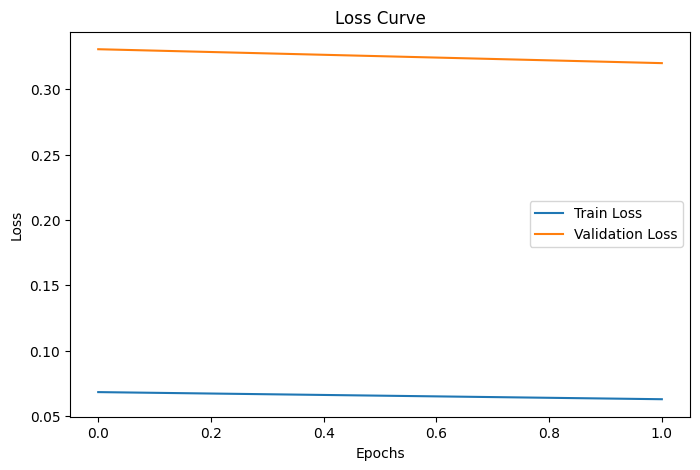

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

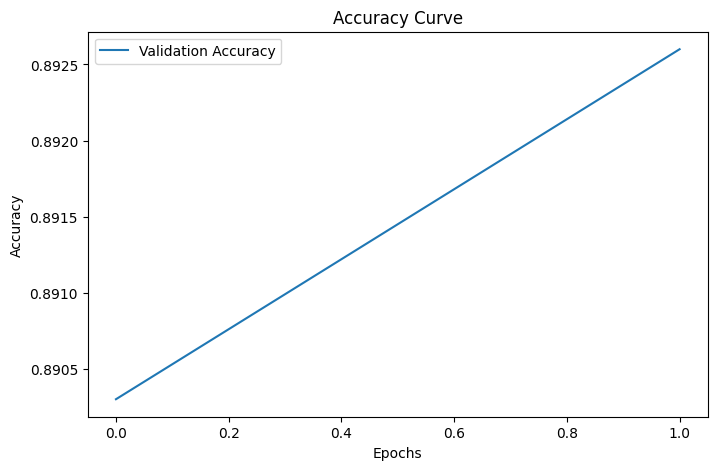

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(val_accuracies, label="Validation Accuracy")

plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

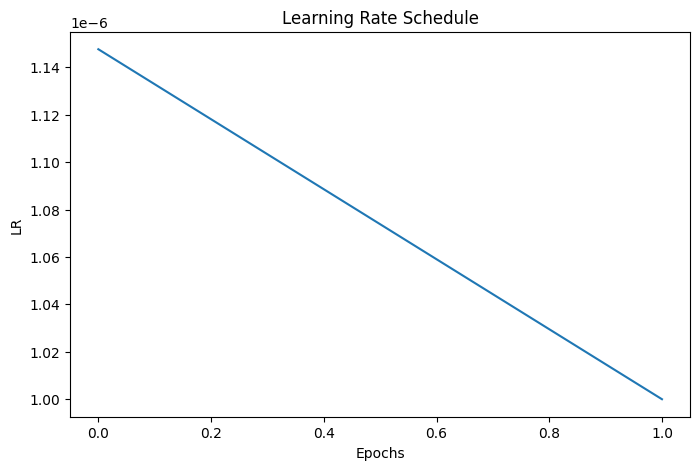

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(lrs)

plt.title("Learning Rate Schedule")
plt.xlabel("Epochs")
plt.ylabel("LR")
plt.show()

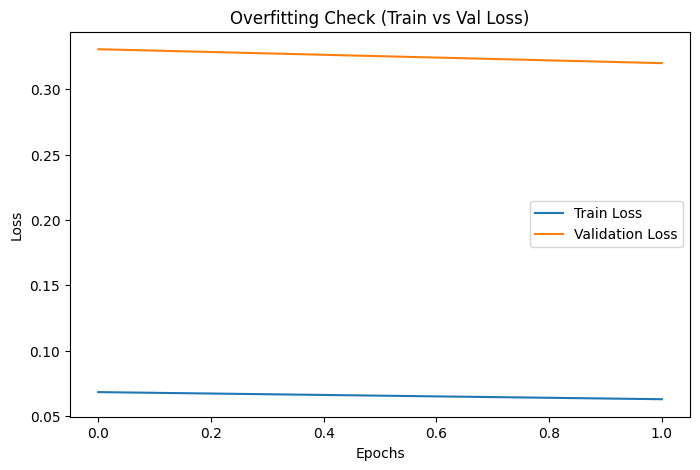

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Overfitting Check (Train vs Val Loss)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
def plot_confusion_matrix(model, test_loader):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for features, labels in test_loader:
            features = features.to(cf.device)

            outputs = model(features)
            preds = outputs.argmax(dim=1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

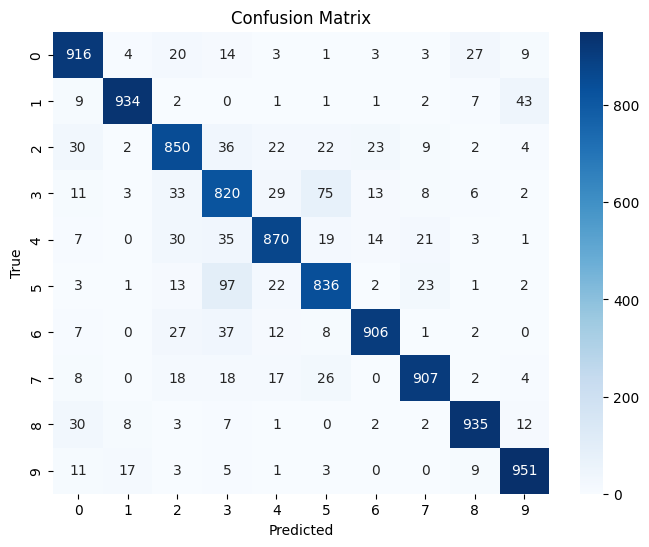

In [ ]:
# Plot confusion matrix on test set
plot_confusion_matrix(model, test_loader)

In [ ]:
import torch
from torchvision import transforms
from PIL import Image


classes = [
    "airplane", "automobile", "bird", "cat",
    "deer", "dog", "frog", "horse",
    "ship", "truck"
]

infer_transform = transforms.Compose([
    transforms.Resize((cf.image_size, cf.image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    )
])

def predict_image(model, image_path, device):
    # load model weights
    checkpoint = torch.load("./checkpoints/best_model.pth", map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    image = Image.open(image_path).convert("RGB")
    image = infer_transform(image)
    image = image.unsqueeze(0).to(device)  # add batch dim

    with torch.no_grad():
        logits = model(image)
        probs = torch.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
        confidence = probs[0, pred_class].item()

    return classes[pred_class], confidence

In [ ]:
# Predict on a CIFAR-10 test sample (no external image file needed)
from torchvision import datasets

classes = [
    "airplane", "automobile", "bird", "cat",
    "deer", "dog", "frog", "horse",
    "ship", "truck"
]

sample_transform = transforms.Compose([
    transforms.Resize((cf.image_size, cf.image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    )
])

test_dataset = datasets.CIFAR10(root="./data", train=False, download=False, transform=sample_transform)
sample_image, true_label = test_dataset[0]

# Load best checkpoint
checkpoint = torch.load("./checkpoints/best_model.pth", map_location=cf.device)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(cf.device)
model.eval()

with torch.no_grad():
    input_tensor = sample_image.unsqueeze(0).to(cf.device)
    logits = model(input_tensor)
    probs = torch.softmax(logits, dim=1)
    pred_class = torch.argmax(probs, dim=1).item()
    confidence = probs[0, pred_class].item()

print(f"True Label  : {classes[true_label]}")
print(f"Predicted   : {classes[pred_class]}")
print(f"Confidence  : {confidence*100:.2f}%")
print(f"Correct     : {classes[true_label] == classes[pred_class]}")


True Label  : cat
Predicted   : cat
Confidence  : 99.96%
Correct     : True
